# Week 3: Data Visualization and Insights Communication
**Healthcare Data Analysis Project: Coronary Artery Disease (UCI Heart Disease Databases)**

Companion notebook to *Week3_Data_Visualization_Plan.docx*. It turns the cleaned Week 2 dataset into the visualizations and dashboard mock-ups described in the plan.

**Contents**
1. Setup, accessible colour palette and contrast checks
2. Key metrics (KPIs)
3. Visualizations V1 to V8, each with the decision it supports
4. A data-driven executive dashboard
5. Wireframes (mock-ups) for dashboards and reports

**Input:** `qa_output/heart_disease_clean.csv` (produced by the Week 2 pipeline). **Output:** PNG figures in `viz_output/`.

## 1. Setup, accessible palette and contrast checks
Colours come from the Okabe-Ito colour-blind-safe palette (Okabe & Ito, 2008). Meaning is never carried by colour alone: shapes, labels and direct annotations are used too. The code below computes WCAG 2.1 contrast ratios so that accessibility is measured, not assumed.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Rectangle
from scipy import stats
from pathlib import Path
from IPython.display import display

DATA = Path("qa_output/heart_disease_clean.csv")
OUT = Path("viz_output"); OUT.mkdir(exist_ok=True)

plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 11, "figure.dpi": 110})

# Okabe-Ito colour-blind-safe palette
BLUE, VERM, ORANGE, SKY, GREEN, PURPLE, GREY, DARK = "#0072B2", "#D55E00", "#E69F00", "#56B4E9", "#009E73", "#CC79A7", "#6B7280", "#1F2937"
C_NO, C_YES = BLUE, VERM      # no disease / disease (also distinguished by marker and label)

def lum(hexc):
    r, g, b = [int(hexc[i:i+2], 16)/255 for i in (1, 3, 5)]
    f = lambda c: c/12.92 if c <= 0.03928 else ((c+0.055)/1.055)**2.4
    return 0.2126*f(r) + 0.7152*f(g) + 0.0722*f(b)
def contrast(a, b="#FFFFFF"):
    la, lb = sorted([lum(a), lum(b)], reverse=True)
    return (la+0.05)/(lb+0.05)

pal = {"Blue (no disease)": BLUE, "Vermillion (disease)": VERM, "Orange": ORANGE, "Sky blue": SKY,
       "Green": GREEN, "Purple": PURPLE, "Grey (text)": GREY, "Dark (text)": DARK}
ct = pd.DataFrame({"colour": pal.keys(), "hex": pal.values(),
                   "contrast_vs_white": [round(contrast(h), 2) for h in pal.values()]})
ct["meets_3:1_graphics"] = ct.contrast_vs_white >= 3
ct["meets_4.5:1_text"] = ct.contrast_vs_white >= 4.5
display(ct)

df = pd.read_csv(DATA)
df["disease"] = df.target.map({0: "No disease", 1: "Disease"})
df["sex_lbl"] = df.sex.map({1: "Male", 0: "Female"})
df["site_lbl"] = df.site.map({"cleveland": "Cleveland (USA)", "hungarian": "Hungary", "switzerland": "Switzerland", "va": "VA Long Beach (USA)"})
df["age_band"] = pd.cut(df.age, [0, 44, 54, 64, 120], labels=["<45", "45-54", "55-64", "65+"])
cp_lbl = {1: "Typical angina", 2: "Atypical angina", 3: "Non-anginal pain", 4: "Asymptomatic"}
df["cp_lbl"] = df.cp.map(cp_lbl)
# Only use values that were actually measured (not imputed) for clinical charts
df["chol_meas"] = df.chol.where(df.chol_missing == 0)
df["thalach_meas"] = df.thalach.where(df.thalach_missing == 0)
df["oldpeak_meas"] = df.oldpeak.where(df.oldpeak_missing == 0)
print(df.shape)

,colour,hex,contrast_vs_white,meets_3:1_graphics,meets_4.5:1_text
0,Blue (no disease),#0072B2,5.19,True,True
1,Vermillion (disease),#D55E00,3.87,True,False
2,Orange,#E69F00,2.25,False,False
3,Sky blue,#56B4E9,2.31,False,False
4,Green,#009E73,3.42,True,False
5,Purple,#CC79A7,3.06,True,False
6,Grey (text),#6B7280,4.83,True,True
7,Dark (text),#1F2937,14.68,True,True


(918, 42)


## 2. Key metrics (KPIs)
The numbers a manager or clinician sees first. Prevalence is shown with a Wilson 95% confidence interval because several sites are small.

In [2]:
def wilson(k, n, z=1.96):
    p = k/n; d = 1 + z**2/n
    c = (p + z**2/(2*n))/d; h = z*np.sqrt(p*(1-p)/n + z**2/(4*n**2))/d
    return c-h, c+h

n_pat = len(df)
prev = df.target.mean()
fill_cols = ["trestbps", "chol", "fbs", "restecg", "thalach", "exang", "oldpeak", "slope"]
completeness = 100*(1 - np.mean([df[f"{c}_missing"].mean() for c in fill_cols]))
site = (df.groupby("site_lbl").agg(patients=("target", "size"), diseased=("target", "sum"),
        mean_age=("age", "mean"), pct_male=("sex", "mean")).round(2))
site["prevalence_%"] = (100*site.diseased/site.patients).round(1)
ci = [wilson(r.diseased, r.patients) for r in site.itertuples()]
site["ci_low_%"] = [round(100*a, 1) for a, b in ci]; site["ci_high_%"] = [round(100*b, 1) for a, b in ci]
site["pct_male"] = (100*site.pct_male).round(0)
kpi = {"Patients": n_pat, "Overall prevalence": f"{100*prev:.1f}%", "Hospitals": df.site.nunique(),
       "Data completeness (8 clinical fields)": f"{completeness:.1f}%"}
print(kpi); display(site)

{'Patients': 918, 'Overall prevalence': '55.3%', 'Hospitals': 4, 'Data completeness (8 clinical fields)': '88.5%'}


,patients,diseased,mean_age,pct_male,prevalence_%,ci_low_%,ci_high_%
site_lbl,,,,,,,
Cleveland (USA),303,139,54.44,68.0,45.9,40.4,51.5
Hungary,293,106,47.82,73.0,36.2,30.9,41.8
Switzerland,123,115,55.32,92.0,93.5,87.7,96.7
VA Long Beach (USA),199,148,59.36,97.0,74.4,67.9,79.9


## 3. Visualizations

### V1. Disease prevalence by hospital, with uncertainty
**Decision supported:** Is a hospital's case-mix different enough that pooled results could mislead? A dot-and-interval chart is used (not a bar chart) because the interval is the message. Sorted from highest to lowest and labelled directly.

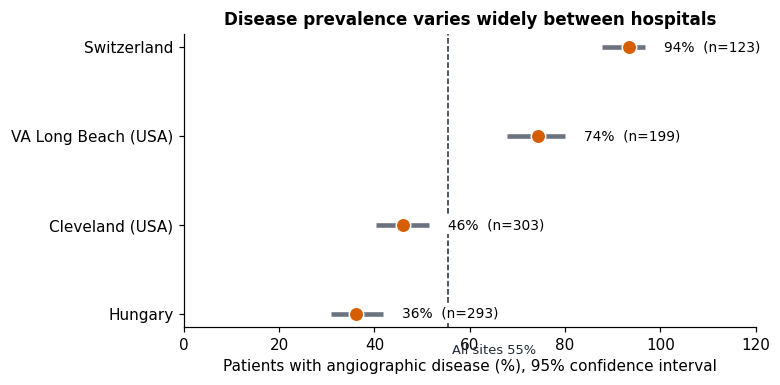

In [3]:
s = site.sort_values("prevalence_%")
fig, ax = plt.subplots(figsize=(7.2, 3.6))
y = np.arange(len(s))
ax.hlines(y, s["ci_low_%"], s["ci_high_%"], color=GREY, lw=3, zorder=1)
ax.scatter(s["prevalence_%"], y, s=90, color=VERM, zorder=2, edgecolor="white")
for yi, (idx, r) in zip(y, s.iterrows()):
    ax.text(r["ci_high_%"]+4, yi, f"{r['prevalence_%']:.0f}%  (n={int(r.patients)})", va="center", fontsize=9, bbox=dict(fc="white", ec="none", pad=1.5))
ax.axvline(100*prev, color=DARK, ls="--", lw=1)
ax.text(100*prev+1, -0.45, f"All sites {100*prev:.0f}%", fontsize=8.5, color=DARK)
ax.set_yticks(y); ax.set_yticklabels(s.index); ax.set_xlim(0, 120)
ax.set_xlabel("Patients with angiographic disease (%), 95% confidence interval")
ax.set_title("Disease prevalence varies widely between hospitals")
fig.tight_layout(); fig.savefig(OUT/"v1_prevalence_by_site.png", dpi=180); plt.show()

### V2. Disease rate by age band and sex
**Decision supported:** Which patient groups should be prioritised for screening or follow-up? A grouped dot plot with one line per sex makes the age gradient and the sex gap readable at once. Cells with fewer than 10 patients are hollow markers to warn against over-reading.

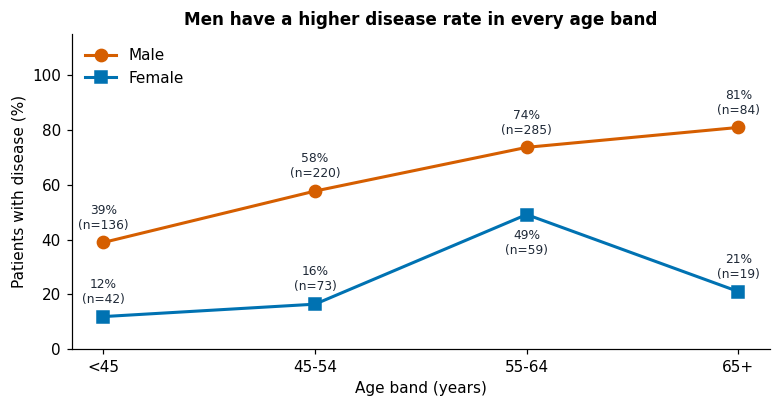

n          rate      
sex_lbl  Female   Male Female  Male
age_band                           
<45        42.0  136.0   0.12  0.39
45-54      73.0  220.0   0.16  0.58
55-64      59.0  285.0   0.49  0.74
65+        19.0   84.0   0.21  0.81

In [4]:
g = df.groupby(["age_band", "sex_lbl"], observed=True).agg(n=("target", "size"), rate=("target", "mean")).reset_index()
fig, ax = plt.subplots(figsize=(7.2, 3.8))
for sx, col, mk in [("Male", VERM, "o"), ("Female", BLUE, "s")]:
    d = g[g.sex_lbl == sx]; x = np.arange(len(d))
    ax.plot(d.age_band.astype(str), 100*d.rate, color=col, lw=2, marker=mk, ms=8, label=sx)
    for xi, r in zip(x, d.itertuples()):
        if r.n < 10: ax.plot(xi, 100*r.rate, mk, ms=8, mfc="white", mec=col, mew=2)
        ax.annotate(f"{100*r.rate:.0f}%\n(n={r.n})", (xi, 100*r.rate), textcoords="offset points",
                    xytext=(0, 9 if sx == "Male" else -26 if r.rate > 0.3 else 9), ha="center", fontsize=8, color=DARK)
ax.set_ylim(0, 115); ax.set_xlabel("Age band (years)"); ax.set_ylabel("Patients with disease (%)")
ax.set_title("Men have a higher disease rate in every age band"); ax.legend(frameon=False, loc="upper left")
if (g.n < 10).any(): fig.text(0.01, 0.01, "Hollow marker = fewer than 10 patients", fontsize=8, color=GREY)
fig.tight_layout(); fig.savefig(OUT/"v2_age_sex_rate.png", dpi=180); plt.show()
display(g.pivot(index="age_band", columns="sex_lbl", values=["n", "rate"]).round(2))

### V3. Chest pain type and disease (100% stacked bars)
**Decision supported:** Which symptom presentations are most concerning? Chest-pain categories are ordered by disease share, and the share is labelled inside each bar.

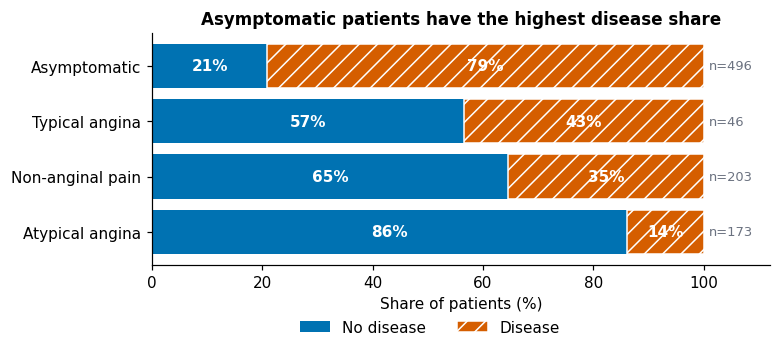

In [5]:
t = pd.crosstab(df.cp_lbl, df.disease, normalize="index")*100
n_cp = df.cp_lbl.value_counts()
t = t.sort_values("Disease")
fig, ax = plt.subplots(figsize=(7.2, 3.4))
ax.barh(t.index, t["No disease"], color=C_NO, label="No disease")
ax.barh(t.index, t["Disease"], left=t["No disease"], color=C_YES, label="Disease", hatch="//", edgecolor="white")
for i, (idx, r) in enumerate(t.iterrows()):
    ax.text(r["No disease"]/2, i, f"{r['No disease']:.0f}%", color="white", ha="center", va="center", fontweight="bold")
    ax.text(r["No disease"]+r["Disease"]/2, i, f"{r['Disease']:.0f}%", color="white", ha="center", va="center", fontweight="bold")
    ax.text(101, i, f"n={n_cp[idx]}", va="center", fontsize=8.5, color=GREY)
ax.set_xlim(0, 112); ax.set_xlabel("Share of patients (%)")
ax.set_title("Asymptomatic patients have the highest disease share")
ax.legend(frameon=False, ncol=2, loc="upper center", bbox_to_anchor=(0.45, -0.18))
fig.tight_layout(); fig.savefig(OUT/"v3_chest_pain.png", dpi=180); plt.show()

### V4. Maximum heart rate versus age
**Decision supported:** Does exercise capacity separate patients with and without disease after accounting for age? A scatter plot with a fitted trend per group. Colour **and** marker shape distinguish groups.

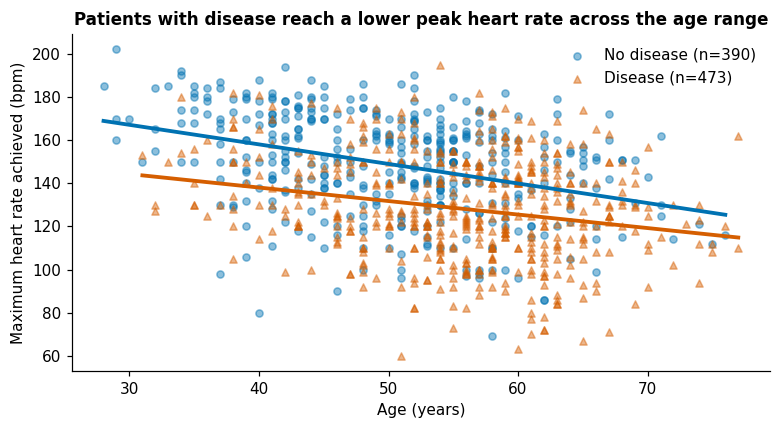

Median max HR by disease status:


disease
Disease       128.0
No disease    151.0
Name: thalach_meas, dtype: float64

In [6]:
d = df.dropna(subset=["thalach_meas"])
fig, ax = plt.subplots(figsize=(7.2, 4))
for lab, col, mk in [("No disease", C_NO, "o"), ("Disease", C_YES, "^")]:
    s_ = d[d.disease == lab]
    ax.scatter(s_.age, s_.thalach_meas, s=22, alpha=.45, color=col, marker=mk, label=f"{lab} (n={len(s_)})")
    b, a = np.polyfit(s_.age, s_.thalach_meas, 1); xs = np.linspace(s_.age.min(), s_.age.max(), 20)
    ax.plot(xs, a + b*xs, color=col, lw=2.5)
ax.set_xlabel("Age (years)"); ax.set_ylabel("Maximum heart rate achieved (bpm)")
ax.set_title("Patients with disease reach a lower peak heart rate across the age range")
ax.legend(frameon=False); fig.tight_layout(); fig.savefig(OUT/"v4_heartrate_age.png", dpi=180); plt.show()
print("Median max HR by disease status:"); display(d.groupby("disease").thalach_meas.median())

### V5. ST depression and exercise angina
**Decision supported:** Which exercise-test findings are worth flagging to the clinician? Box plots with the sample size under each box, plus a small table of exercise-angina rates.

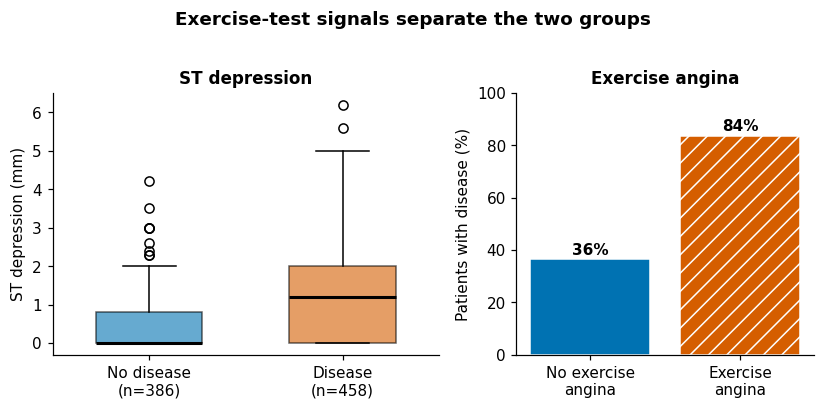

In [7]:
d = df.dropna(subset=["oldpeak_meas"])
fig, axes = plt.subplots(1, 2, figsize=(7.6, 3.6), gridspec_kw={"width_ratios": [1.3, 1]})
bp = axes[0].boxplot([d[d.disease == k].oldpeak_meas for k in ["No disease", "Disease"]],
                     tick_labels=[f"No disease\n(n={(d.disease=='No disease').sum()})", f"Disease\n(n={(d.disease=='Disease').sum()})"],
                     patch_artist=True, widths=.55, medianprops={"color": "black", "lw": 2})
for p, c in zip(bp["boxes"], [C_NO, C_YES]): p.set_facecolor(c); p.set_alpha(.6)
axes[0].set_ylabel("ST depression (mm)"); axes[0].set_title("ST depression")
ex = df[df.exang_missing == 0].groupby("exang").target.mean()*100
axes[1].bar(["No exercise\nangina", "Exercise\nangina"], ex.values, color=[C_NO, C_YES], hatch=["", "//"], edgecolor="white")
for i, v in enumerate(ex.values): axes[1].text(i, v+2, f"{v:.0f}%", ha="center", fontweight="bold")
axes[1].set_ylim(0, 100); axes[1].set_ylabel("Patients with disease (%)"); axes[1].set_title("Exercise angina")
fig.suptitle("Exercise-test signals separate the two groups", fontweight="bold", y=1.02)
fig.tight_layout(); fig.savefig(OUT/"v5_exercise_signals.png", dpi=180, bbox_inches="tight"); plt.show()

### V6. Ranked association with disease
**Decision supported:** Where should analysts focus first? A ranked bar chart of Spearman correlation with the disease flag, using measured values only. Correlation is a screening tool and is **not** causal; the caption says so.

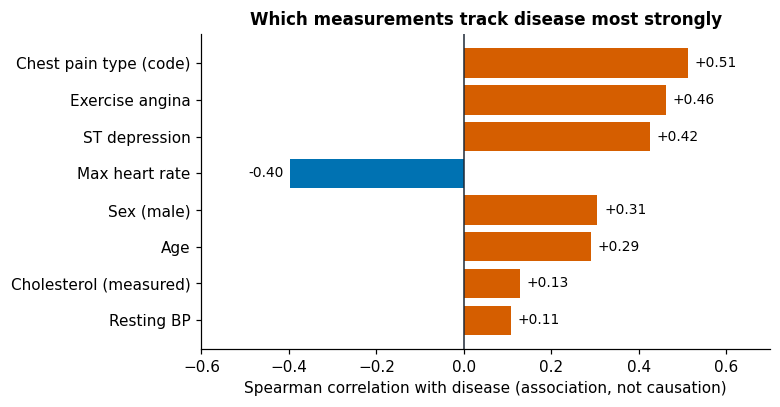

,variable,rho,n
6,Resting BP,0.11,858
7,Cholesterol (measured),0.13,717
3,Age,0.29,918
4,Sex (male),0.31,918
2,Max heart rate,-0.40,863
1,ST depression,0.42,844
0,Exercise angina,0.46,863
5,Chest pain type (code),0.51,918


In [8]:
cand = {"Exercise angina": "exang", "ST depression": "oldpeak_meas", "Max heart rate": "thalach_meas", "Age": "age",
        "Sex (male)": "sex", "Chest pain type (code)": "cp", "Resting BP": "trestbps", "Cholesterol (measured)": "chol_meas"}
rows = []
for lab, c in cand.items():
    x = df[[c, "target"]].dropna()
    if c in ("trestbps", "exang"): x = df.loc[df[f"{c}_missing"] == 0, [c, "target"]]
    r, p = stats.spearmanr(x[c], x.target); rows.append((lab, r, len(x)))
cr = pd.DataFrame(rows, columns=["variable", "rho", "n"]).sort_values("rho", key=abs)
fig, ax = plt.subplots(figsize=(7.2, 3.8))
cols = [C_YES if r > 0 else C_NO for r in cr.rho]
ax.barh(cr.variable, cr.rho, color=cols)
for i, r in enumerate(cr.itertuples()):
    ax.text(r.rho + (0.015 if r.rho > 0 else -0.015), i, f"{r.rho:+.2f}", va="center", ha="left" if r.rho > 0 else "right", fontsize=9)
ax.axvline(0, color=DARK, lw=1); ax.set_xlim(-0.6, 0.7)
ax.set_xlabel("Spearman correlation with disease (association, not causation)")
ax.set_title("Which measurements track disease most strongly")
fig.tight_layout(); fig.savefig(OUT/"v6_ranked_association.png", dpi=180); plt.show(); display(cr.round(2))

### V7. Data completeness heatmap
**Decision supported:** Which hospital data can be trusted for which analysis? Shows the share of values actually measured. This view is what turns the Week 2 quality work into something a data steward can act on.

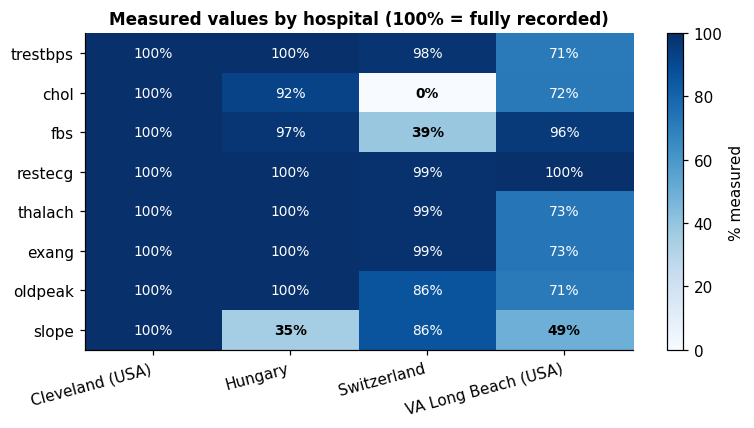

In [9]:
vars_ = ["trestbps", "chol", "fbs", "restecg", "thalach", "exang", "oldpeak", "slope"]
comp = pd.DataFrame({v: 100*(1 - df.groupby("site_lbl")[f"{v}_missing"].mean()) for v in vars_}).T
fig, ax = plt.subplots(figsize=(7.2, 4))
im = ax.imshow(comp.values, cmap="Blues", vmin=0, vmax=100, aspect="auto")
ax.set_xticks(range(comp.shape[1])); ax.set_xticklabels(comp.columns, rotation=15, ha="right")
ax.set_yticks(range(comp.shape[0])); ax.set_yticklabels(comp.index)
for i in range(comp.shape[0]):
    for j in range(comp.shape[1]):
        v = comp.values[i, j]; ax.text(j, i, f"{v:.0f}%", ha="center", va="center", color="white" if v > 55 else "black", fontsize=9, fontweight="bold" if v < 50 else None)
ax.set_title("Measured values by hospital (100% = fully recorded)"); fig.colorbar(im, ax=ax, label="% measured")
fig.tight_layout(); fig.savefig(OUT/"v7_completeness.png", dpi=180); plt.show()

### V8. Small multiples: disease rate by sex within each hospital
**Decision supported:** Is the sex gap consistent across sites, or driven by one hospital? Small multiples share the same axis so panels can be compared directly (Tufte, 1983).

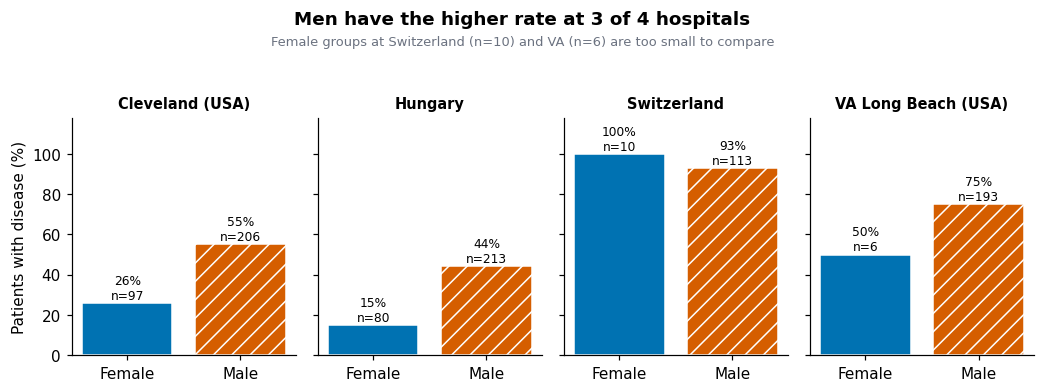

In [10]:
sites = list(df.site_lbl.unique())
fig, axes = plt.subplots(1, 4, figsize=(9.6, 3.2), sharey=True)
for ax, st in zip(axes, sites):
    d = df[df.site_lbl == st].groupby("sex_lbl").agg(n=("target", "size"), r=("target", "mean"))
    d = d.reindex(["Female", "Male"])
    ax.bar(d.index, 100*d.r, color=[BLUE, VERM], hatch=["", "//"], edgecolor="white")
    for i, (idx, r) in enumerate(d.iterrows()):
        ax.text(i, 100*r.r + 2, f"{100*r.r:.0f}%\nn={int(r.n)}", ha="center", fontsize=8)
    ax.set_title(st, fontsize=9.5); ax.set_ylim(0, 118)
axes[0].set_ylabel("Patients with disease (%)")
fig.suptitle("Men have the higher rate at 3 of 4 hospitals", fontweight="bold", y=1.1)
fig.text(0.5, 1.0, "Female groups at Switzerland (n=10) and VA (n=6) are too small to compare", ha="center", fontsize=8.5, color=GREY)
fig.tight_layout(); fig.savefig(OUT/"v8_small_multiples.png", dpi=180, bbox_inches="tight"); plt.show()

## 4. Data-driven executive dashboard
Combines KPI tiles and three of the charts above on one screen, following an inverted-pyramid layout: headline numbers first, then supporting evidence, then detail on demand.

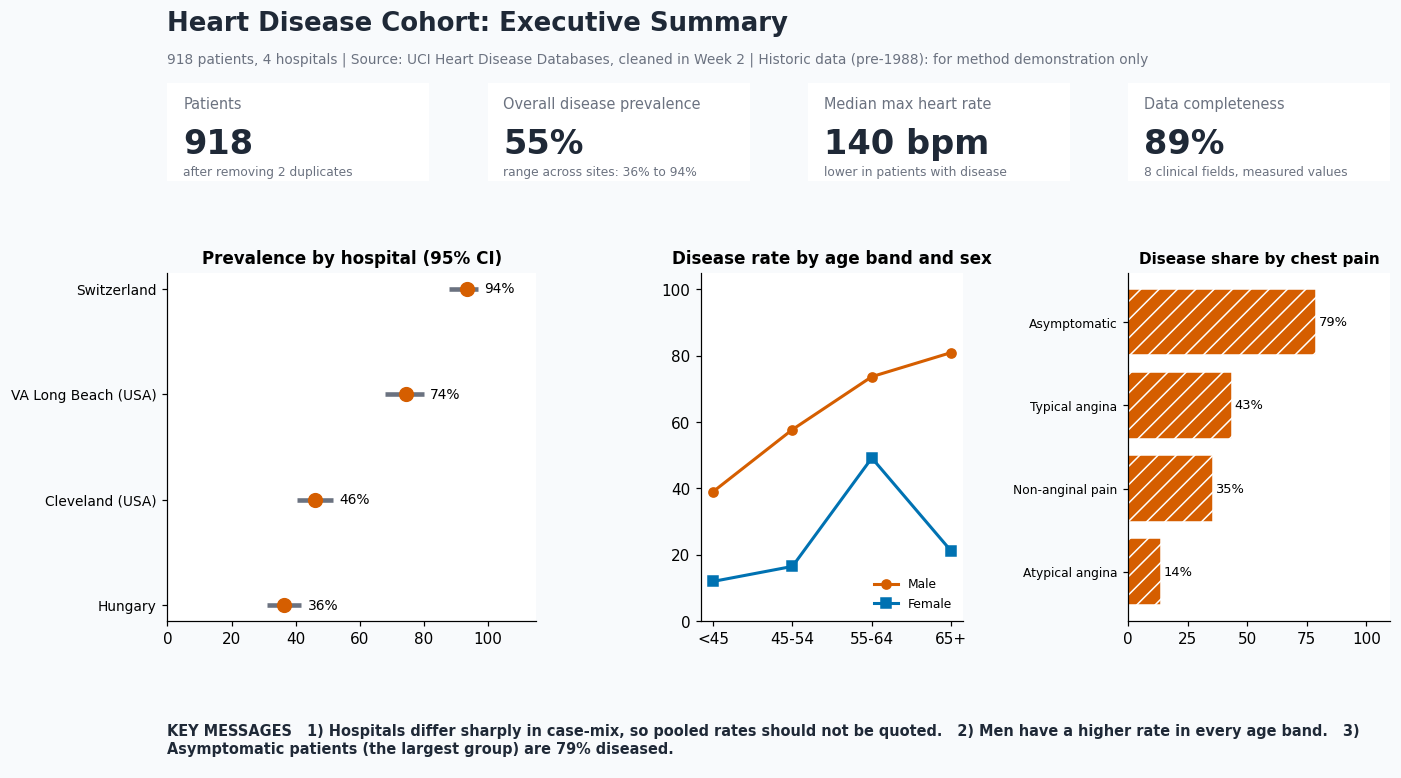

In [11]:
fig = plt.figure(figsize=(13, 7.4), facecolor="#F8FAFC")
gs = fig.add_gridspec(3, 12, height_ratios=[0.9, 3.2, 0.5], hspace=0.55, wspace=1.2, left=0.115, right=0.97, top=0.88, bottom=0.04)
fig.text(0.115, 0.945, "Heart Disease Cohort: Executive Summary", fontsize=17, fontweight="bold", color=DARK)
fig.text(0.115, 0.905, "918 patients, 4 hospitals | Source: UCI Heart Disease Databases, cleaned in Week 2 | Historic data (pre-1988): for method demonstration only", fontsize=9, color=GREY)

tiles = [("Patients", f"{n_pat:,}", "after removing 2 duplicates"), ("Overall disease prevalence", f"{100*prev:.0f}%", "range across sites: 36% to 94%"),
         ("Median max heart rate", f"{df.thalach_meas.median():.0f} bpm", "lower in patients with disease"), ("Data completeness", f"{completeness:.0f}%", "8 clinical fields, measured values")]
for i, (t_, v_, s_) in enumerate(tiles):
    ax = fig.add_subplot(gs[0, i*3:(i+1)*3]); ax.axis("off")
    ax.add_patch(FancyBboxPatch((0, 0), 1, 1, boxstyle="round,pad=0.02", fc="white", ec="#CBD5E1", transform=ax.transAxes))
    ax.text(0.06, 0.74, t_, fontsize=9.5, color=GREY, transform=ax.transAxes)
    ax.text(0.06, 0.28, v_, fontsize=22, fontweight="bold", color=DARK, transform=ax.transAxes)
    ax.text(0.06, 0.06, s_, fontsize=8, color=GREY, transform=ax.transAxes)

ax1 = fig.add_subplot(gs[1, 0:4]); s = site.sort_values("prevalence_%"); y = np.arange(len(s))
ax1.hlines(y, s["ci_low_%"], s["ci_high_%"], color=GREY, lw=3); ax1.scatter(s["prevalence_%"], y, s=80, color=VERM, zorder=3)
for yi, (idx, r) in zip(y, s.iterrows()): ax1.text(r["ci_high_%"]+2, yi, f"{r['prevalence_%']:.0f}%", va="center", fontsize=9)
ax1.set_yticks(y); ax1.set_yticklabels(s.index, fontsize=9); ax1.set_xlim(0, 115); ax1.set_title("Prevalence by hospital (95% CI)")
ax2 = fig.add_subplot(gs[1, 5:8])
for sx, col, mk in [("Male", VERM, "o"), ("Female", BLUE, "s")]:
    dd = g[g.sex_lbl == sx]; ax2.plot(dd.age_band.astype(str), 100*dd.rate, color=col, lw=2, marker=mk, label=sx)
ax2.set_ylim(0, 105); ax2.legend(frameon=False, fontsize=8, loc="lower right"); ax2.set_title("Disease rate by age band and sex")
ax3 = fig.add_subplot(gs[1, 9:12]); t3 = t.copy()
ax3.barh(t3.index, t3["Disease"], color=C_YES, hatch="//", edgecolor="white")
for i, v in enumerate(t3["Disease"]): ax3.text(v+1, i, f"{v:.0f}%", va="center", fontsize=8.5)
ax3.set_xlim(0, 110); ax3.set_title("Disease share by chest pain", fontsize=10); ax3.tick_params(axis="y", labelsize=8)
ax4 = fig.add_subplot(gs[2, :]); ax4.axis("off")
ax4.text(0, 0.5, "KEY MESSAGES   1) Hospitals differ sharply in case-mix, so pooled rates should not be quoted.   2) Men have a higher rate in every age band.   3) Asymptomatic patients (the largest group) are 79% diseased.",
         fontsize=9.5, fontweight="bold", color=DARK, va="center", wrap=True)
fig.savefig(OUT/"dashboard_executive.png", dpi=170, facecolor=fig.get_facecolor()); plt.show()

## 5. Wireframes (mock-ups)
Low-fidelity grayscale wireframes keep the discussion on layout and information hierarchy, not colour or styling. Numbered markers refer to the annotation table in the report.

In [12]:
rng = np.random.default_rng(3)
G1, G2, G3, INK = "#F1F5F9", "#CBD5E1", "#94A3B8", "#1E293B"

def box(ax, x, y, w, h, label="", fc=G1, fs=8, bold=False, tc=INK, ec=G3):
    ax.add_patch(Rectangle((x, y), w, h, fc=fc, ec=ec, lw=1))
    if label: ax.text(x+w/2, y+h/2, label, ha="center", va="center", fontsize=fs, fontweight="bold" if bold else None, color=tc, wrap=True)
def tag(ax, x, y, n):
    ax.add_patch(plt.Circle((x, y), 1.5, color=INK, zorder=5)); ax.text(x, y, str(n), color="white", ha="center", va="center", fontsize=8, fontweight="bold", zorder=6)
def mini_bars(ax, x, y, w, h, n=5, horizontal=False):
    v = rng.uniform(.3, 1, n)
    for i, vi in enumerate(v):
        if horizontal: ax.add_patch(Rectangle((x+2, y+h-(i+1)*h/(n+.5)), vi*(w-4), h/(n+1.5), fc=G3, ec="none"))
        else: ax.add_patch(Rectangle((x+2+i*(w-4)/n, y+2), (w-4)/n*.7, vi*(h-6), fc=G3, ec="none"))
def mini_line(ax, x, y, w, h):
    xs = np.linspace(x+3, x+w-3, 8); ax.plot(xs, y+4+np.cumsum(rng.uniform(0, 1, 8))/8*(h-10), color=INK, lw=1.5)
def mini_scatter(ax, x, y, w, h):
    ax.scatter(x+3+rng.random(30)*(w-6), y+3+rng.random(30)*(h-8), s=6, color=G3)
def mini_heat(ax, x, y, w, h, r=5, c=4):
    for i in range(r):
        for j in range(c): ax.add_patch(Rectangle((x+2+j*(w-4)/c, y+2+i*(h-4)/r), (w-4)/c-.5, (h-4)/r-.5, fc=str(0.35+0.55*rng.random()) , ec="none"))
def canvas(w, h, title, sub):
    fig, ax = plt.subplots(figsize=(w/10, h/10)); ax.set_xlim(0, w); ax.set_ylim(0, h); ax.axis("off"); ax.invert_yaxis()
    ax.add_patch(Rectangle((0, 0), w, h, fc="white", ec=INK, lw=2))
    box(ax, 0, 0, w, 8, "", fc=INK); ax.text(3, 4, title, color="white", fontsize=10, fontweight="bold", va="center")
    ax.text(w-3, 4, sub, color="#CBD5E1", fontsize=8, va="center", ha="right"); return fig, ax

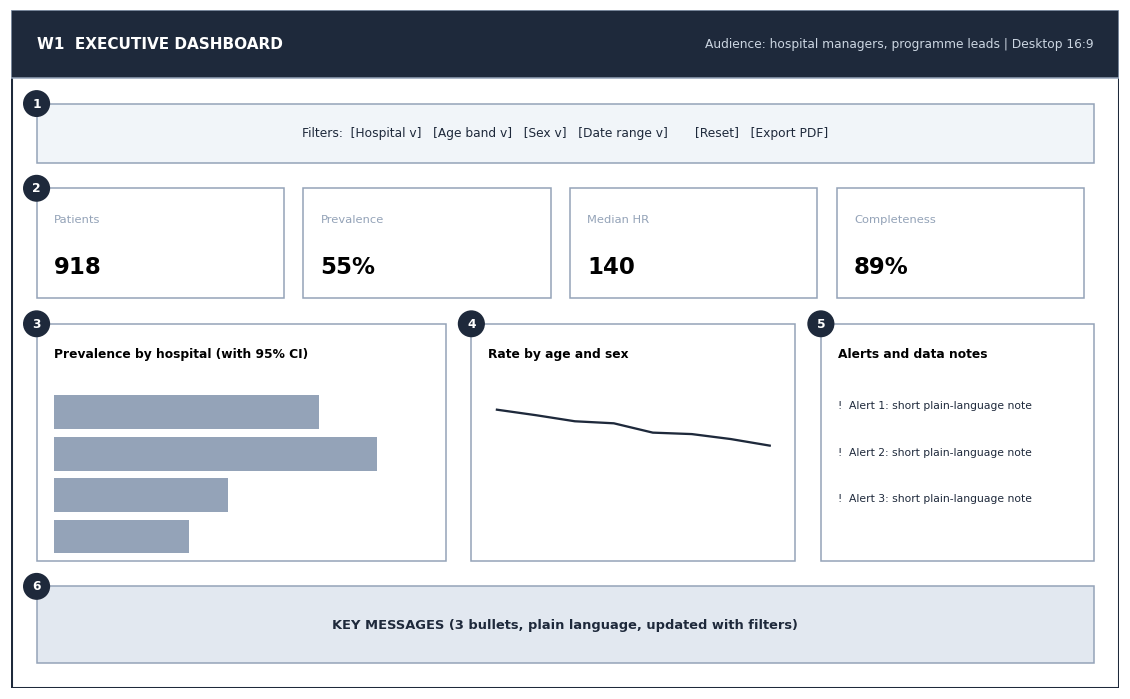

In [13]:
# W1: Executive dashboard (desktop)
fig, ax = canvas(130, 80, "W1  EXECUTIVE DASHBOARD", "Audience: hospital managers, programme leads | Desktop 16:9")
box(ax, 3, 11, 124, 7, "Filters:  [Hospital v]   [Age band v]   [Sex v]   [Date range v]       [Reset]   [Export PDF]", fs=8); tag(ax, 3, 11, 1)
for i, (t_, v_) in enumerate([("Patients", "918"), ("Prevalence", "55%"), ("Median HR", "140"), ("Completeness", "89%")]):
    box(ax, 3+i*31.3, 21, 29, 13, "", fc="white"); ax.text(5+i*31.3, 25, t_, fontsize=7.5, color=G3); ax.text(5+i*31.3, 31, v_, fontsize=15, fontweight="bold")
tag(ax, 3, 21, 2)
box(ax, 3, 37, 48, 28, "", fc="white"); ax.text(5, 41, "Prevalence by hospital (with 95% CI)", fontsize=8, fontweight="bold"); mini_bars(ax, 3, 43, 48, 22, 4, True); tag(ax, 3, 37, 3)
box(ax, 54, 37, 38, 28, "", fc="white"); ax.text(56, 41, "Rate by age and sex", fontsize=8, fontweight="bold"); mini_line(ax, 54, 43, 38, 22); tag(ax, 54, 37, 4)
box(ax, 95, 37, 32, 28, "", fc="white"); ax.text(97, 41, "Alerts and data notes", fontsize=8, fontweight="bold")
for i in range(3): ax.text(97, 47+i*5.5, f"!  Alert {i+1}: short plain-language note", fontsize=7, color=INK)
tag(ax, 95, 37, 5)
box(ax, 3, 68, 124, 9, "KEY MESSAGES (3 bullets, plain language, updated with filters)", fc="#E2E8F0", fs=8.5, bold=True); tag(ax, 3, 68, 6)
fig.savefig(OUT/"wireframe_w1_executive.png", dpi=170, bbox_inches="tight"); plt.show()

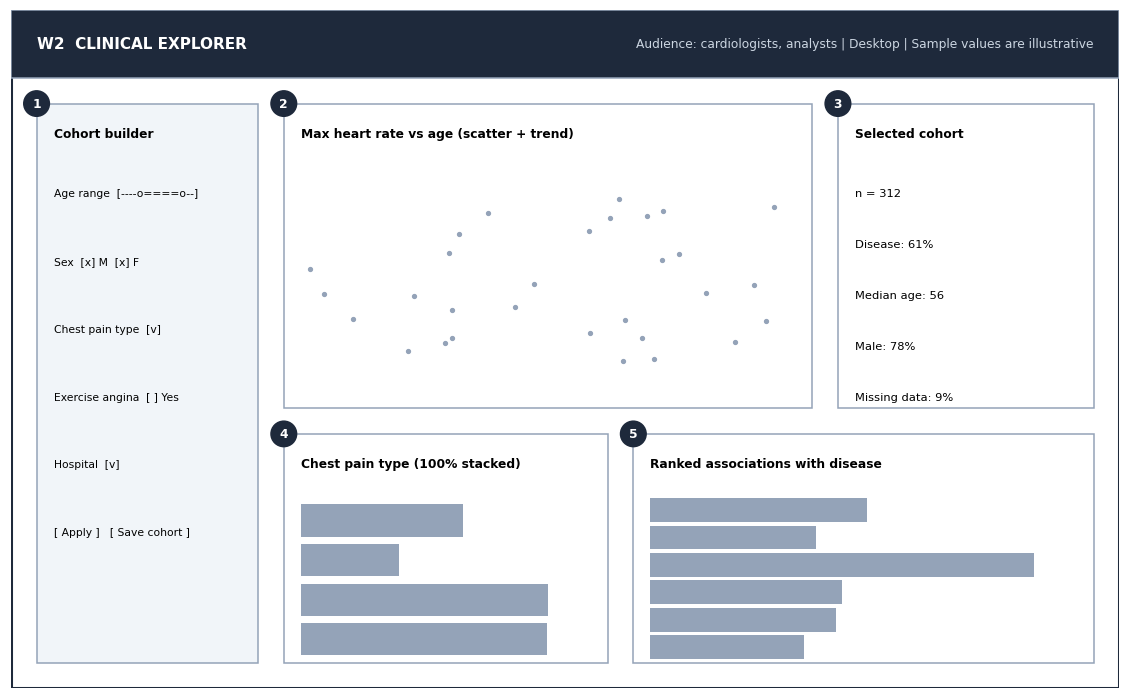

In [14]:
# W2: Clinical explorer
fig, ax = canvas(130, 80, "W2  CLINICAL EXPLORER", "Audience: cardiologists, analysts | Desktop | Sample values are illustrative")
box(ax, 3, 11, 26, 66, "", fc=G1); ax.text(5, 15, "Cohort builder", fontsize=8, fontweight="bold")
for i, l in enumerate(["Age range  [----o====o--]", "Sex  [x] M  [x] F", "Chest pain type  [v]", "Exercise angina  [ ] Yes", "Hospital  [v]", "[ Apply ]   [ Save cohort ]"]):
    ax.text(5, 22+i*8, l, fontsize=7); 
tag(ax, 3, 11, 1)
box(ax, 32, 11, 62, 36, "", fc="white"); ax.text(34, 15, "Max heart rate vs age (scatter + trend)", fontsize=8, fontweight="bold"); mini_scatter(ax, 32, 17, 62, 30); tag(ax, 32, 11, 2)
box(ax, 97, 11, 30, 36, "", fc="white"); ax.text(99, 15, "Selected cohort", fontsize=8, fontweight="bold")
for i, l in enumerate(["n = 312", "Disease: 61%", "Median age: 56", "Male: 78%", "Missing data: 9%"]): ax.text(99, 22+i*6, l, fontsize=7.5)
tag(ax, 97, 11, 3)
box(ax, 32, 50, 38, 27, "", fc="white"); ax.text(34, 54, "Chest pain type (100% stacked)", fontsize=8, fontweight="bold"); mini_bars(ax, 32, 56, 38, 21, 4, True); tag(ax, 32, 50, 4)
box(ax, 73, 50, 54, 27, "", fc="white"); ax.text(75, 54, "Ranked associations with disease", fontsize=8, fontweight="bold"); mini_bars(ax, 73, 56, 54, 21, 6, True); tag(ax, 73, 50, 5)
fig.savefig(OUT/"wireframe_w2_clinical.png", dpi=170, bbox_inches="tight"); plt.show()

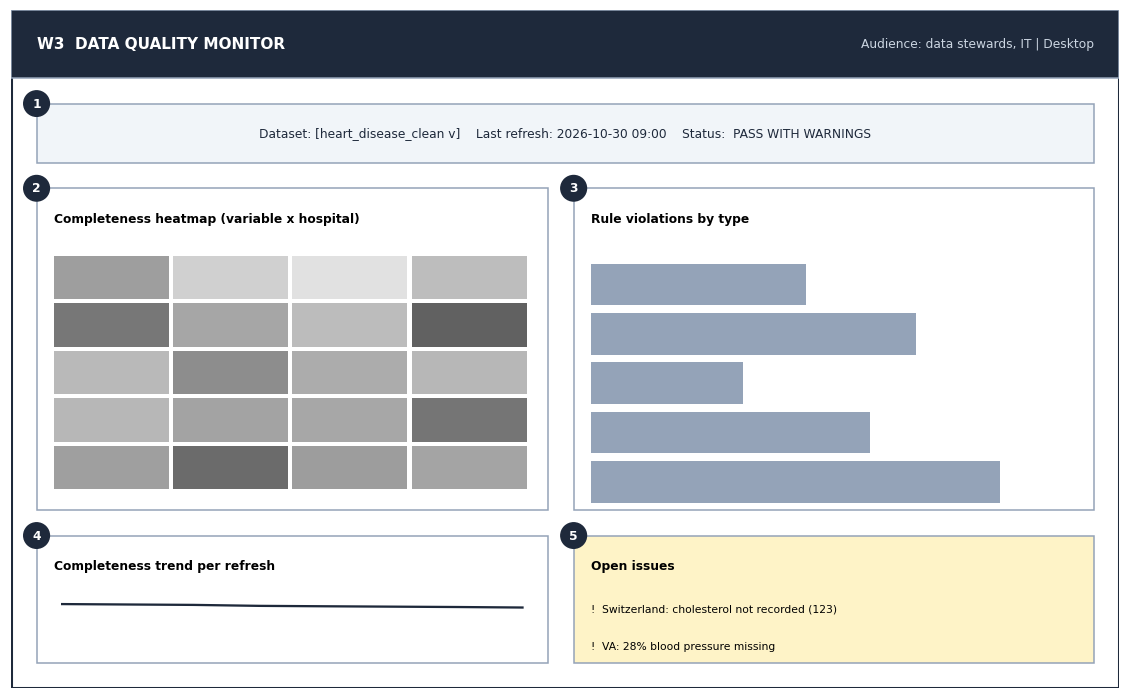

In [15]:
# W3: Data quality monitor
fig, ax = canvas(130, 80, "W3  DATA QUALITY MONITOR", "Audience: data stewards, IT | Desktop")
box(ax, 3, 11, 124, 7, "Dataset: [heart_disease_clean v]    Last refresh: 2026-10-30 09:00    Status:  PASS WITH WARNINGS", fs=8); tag(ax, 3, 11, 1)
box(ax, 3, 21, 60, 38, "", fc="white"); ax.text(5, 25, "Completeness heatmap (variable x hospital)", fontsize=8, fontweight="bold"); mini_heat(ax, 3, 27, 60, 32); tag(ax, 3, 21, 2)
box(ax, 66, 21, 61, 38, "", fc="white"); ax.text(68, 25, "Rule violations by type", fontsize=8, fontweight="bold"); mini_bars(ax, 66, 27, 61, 32, 5, True); tag(ax, 66, 21, 3)
box(ax, 3, 62, 60, 15, "", fc="white"); ax.text(5, 66, "Completeness trend per refresh", fontsize=8, fontweight="bold"); mini_line(ax, 3, 66, 60, 11); tag(ax, 3, 62, 4)
box(ax, 66, 62, 61, 15, "", fc="#FEF3C7"); ax.text(68, 66, "Open issues", fontsize=8, fontweight="bold")
for i, l in enumerate(["Switzerland: cholesterol not recorded (123)", "VA: 28% blood pressure missing"]): ax.text(68, 71+i*4.5, "!  "+l, fontsize=7)
tag(ax, 66, 62, 5)
fig.savefig(OUT/"wireframe_w3_quality.png", dpi=170, bbox_inches="tight"); plt.show()

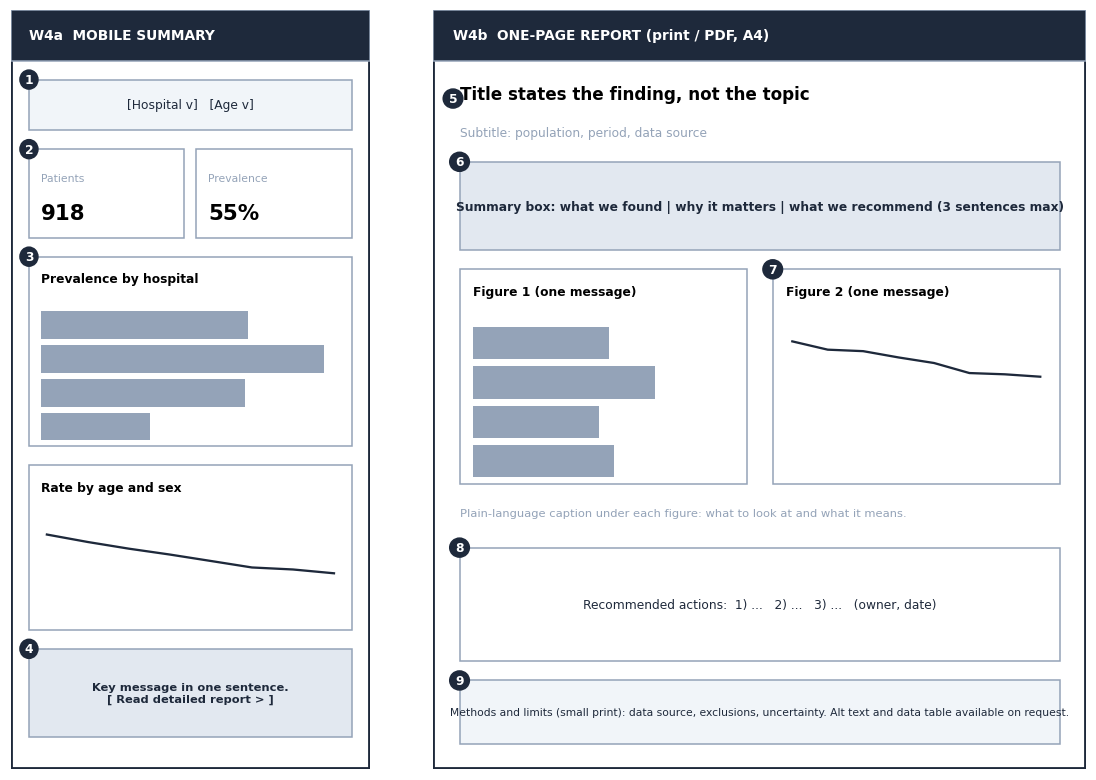

In [16]:
# W4: Mobile summary + printable one-page report
fig, axes = plt.subplots(1, 2, figsize=(10.5, 7.2), gridspec_kw={"width_ratios": [0.55, 1]})
ax = axes[0]; ax.set_xlim(0, 60); ax.set_ylim(0, 120); ax.axis("off"); ax.invert_yaxis()
ax.add_patch(Rectangle((0, 0), 60, 120, fc="white", ec=INK, lw=2.5)); box(ax, 0, 0, 60, 8, "", fc=INK); ax.text(3, 4, "W4a  MOBILE SUMMARY", color="white", fontsize=9, fontweight="bold", va="center")
box(ax, 3, 11, 54, 8, "[Hospital v]   [Age v]", fs=8); tag(ax, 3, 11, 1)
box(ax, 3, 22, 26, 14, "", fc="white"); ax.text(5, 27, "Patients", fontsize=7, color=G3); ax.text(5, 33, "918", fontsize=14, fontweight="bold")
box(ax, 31, 22, 26, 14, "", fc="white"); ax.text(33, 27, "Prevalence", fontsize=7, color=G3); ax.text(33, 33, "55%", fontsize=14, fontweight="bold"); tag(ax, 3, 22, 2)
box(ax, 3, 39, 54, 30, "", fc="white"); ax.text(5, 43, "Prevalence by hospital", fontsize=8, fontweight="bold"); mini_bars(ax, 3, 45, 54, 24, 4, True); tag(ax, 3, 39, 3)
box(ax, 3, 72, 54, 26, "", fc="white"); ax.text(5, 76, "Rate by age and sex", fontsize=8, fontweight="bold"); mini_line(ax, 3, 78, 54, 20)
box(ax, 3, 101, 54, 14, "Key message in one sentence.\n[ Read detailed report > ]", fc="#E2E8F0", fs=7.5, bold=True); tag(ax, 3, 101, 4)
ax = axes[1]; ax.set_xlim(0, 100); ax.set_ylim(0, 120); ax.axis("off"); ax.invert_yaxis()
ax.add_patch(Rectangle((0, 0), 100, 120, fc="white", ec=INK, lw=2.5)); box(ax, 0, 0, 100, 8, "", fc=INK); ax.text(3, 4, "W4b  ONE-PAGE REPORT (print / PDF, A4)", color="white", fontsize=9, fontweight="bold", va="center")
ax.text(4, 14, "Title states the finding, not the topic", fontsize=11, fontweight="bold"); ax.text(4, 20, "Subtitle: population, period, data source", fontsize=8, color=G3); tag(ax, 3, 14, 5)
box(ax, 4, 24, 92, 14, "Summary box: what we found | why it matters | what we recommend (3 sentences max)", fc="#E2E8F0", fs=8, bold=True); tag(ax, 4, 24, 6)
box(ax, 4, 41, 44, 34, "", fc="white"); ax.text(6, 45, "Figure 1 (one message)", fontsize=8, fontweight="bold"); mini_bars(ax, 4, 47, 44, 28, 4, True)
box(ax, 52, 41, 44, 34, "", fc="white"); ax.text(54, 45, "Figure 2 (one message)", fontsize=8, fontweight="bold"); mini_line(ax, 52, 47, 44, 28); tag(ax, 52, 41, 7)
ax.text(4, 80, "Plain-language caption under each figure: what to look at and what it means.", fontsize=7.5, color=G3)
box(ax, 4, 85, 92, 18, "Recommended actions:  1) ...   2) ...   3) ...   (owner, date)", fc="white", fs=8); tag(ax, 4, 85, 8)
box(ax, 4, 106, 92, 10, "Methods and limits (small print): data source, exclusions, uncertainty. Alt text and data table available on request.", fc=G1, fs=7); tag(ax, 4, 106, 9)
fig.tight_layout(); fig.savefig(OUT/"wireframe_w4_mobile_report.png", dpi=170, bbox_inches="tight"); plt.show()

## 6. Summary
All figures are saved in `viz_output/`. Each visualization maps to a decision in the report's decision-support table. Key patterns from this data:
- Hospitals differ sharply in prevalence, so uncertainty and case-mix must be shown, never hidden.
- Men have a higher disease rate in every age band, and at Cleveland, Hungary and VA (Swiss and VA female groups are very small).
- Asymptomatic patients are the largest group (496) and 79% have disease, so absence of symptoms is not a safe signal. This partly reflects who was referred for angiography.
- Lower peak heart rate, ST depression and exercise angina separate the groups.
- Completeness varies by hospital, so the data-quality view belongs in the same toolkit as the clinical views.

*Data are historical (collected before 1988) and are used to demonstrate visualization method, not to guide patient care.*